# IND320 — Project Part 4

- **By:** Agop Haroun
- **GitHub repository:** [G0KU-DOTCOM/Streamlit_dashboard](https://github.com/G0KU-DOTCOM/Streamlit_dashboard)
- **Streamlit application:** [ind320dashboard.streamlit.app](https://ind320dashboard.streamlit.app)

### AI usage

Codex helped identify and verify the overlapping test period, inspect the Norges Bank API response, implement and test the exchange rate downloader, and reuse the existing project readers to collect the NO3 source samples.

## 1. Data preparation

### 1.1 Choose the test region and period

Use **NO3** from **14 October through 29 December 2024**. The project includes hourly ERA5 weather for NO3 throughout 2024. The ENTSO-E snapshot includes the NO3–SE2 connection from 11 October 2024. The chosen period starts with the first complete Monday–Sunday week in the overlap and ends on the last Sunday covered by the 2024 weather file. The local NVE history cache contains one NO3 observation for each week (ISO weeks 42–52), and the local ENTSO-E archive contains 1,849 distinct NO3–SE2 hours in the period.

The period includes the switch to winter time on 27 October and the Christmas holidays. These give us specific dates to inspect when we compare hourly timestamps and currency publication dates. The 11 weeks are a test window for combining the data.

The cell below checks that the selected dates fit inside both existing hourly data ranges. The [weather file](../data/weather/NO3_era5_2024-01-01_2024-12-31_hourly.csv.gz) provides the weather timestamps and the [snapshot plan](../entsoe_plan.json) provides ENTSO-E coverage.

In [1]:
import json
from datetime import date, datetime, time, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo

import pandas as pd

# The notebook can run from the project root or the notebooks folder.
project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent

region = 'NO3'
nve_area_type, nve_area_number = 'EL', 3
entsoe_connection = 'NO3-SE2'
test_start = date(2024, 10, 14)
test_last_date = date(2024, 12, 29)
test_end = test_last_date + timedelta(days=1)
assert test_start.weekday() == test_end.weekday() == 0, 'Use whole calendar weeks.'

# Express the chosen local date boundaries as instants to check source coverage.
oslo = ZoneInfo('Europe/Oslo')
window_start = datetime.combine(test_start, time.min, tzinfo=oslo)
window_end = datetime.combine(test_end, time.min, tzinfo=oslo)

with (project_root / 'entsoe_plan.json').open() as f:
    entsoe_plan = json.load(f)
entsoe_start = datetime.fromisoformat(entsoe_plan['period']['start_inclusive'])
entsoe_end = datetime.fromisoformat(entsoe_plan['period']['end_exclusive'])
assert entsoe_start <= window_start < window_end <= entsoe_end
assert any(item['connection'] == entsoe_connection for item in entsoe_plan['connections'])

weather_file = project_root / 'data/weather/NO3_era5_2024-01-01_2024-12-31_hourly.csv.gz'
weather_times = pd.read_csv(weather_file, usecols=['time'], parse_dates=['time'])['time']
assert weather_times.min() <= window_start < window_end <= weather_times.max()

week_count = (test_end - test_start).days // 7
print(f'{region} | {test_start:%d %b} to {test_last_date:%d %b %Y} | {week_count} full weeks')
print(f'Inside the saved weather period and the {entsoe_connection} snapshot period.')

NO3 | 14 Oct to 29 Dec 2024 | 11 full weeks
Inside the saved weather period and the NO3-SE2 snapshot period.


### 1.2 Download EUR and USD exchange rates

The [Norges Bank API](https://www.norges-bank.no/en/topics/Statistics/open-data/guide-data-warehouse/) provides daily EUR/NOK and USD/NOK spot rates. The shared [downloader](../dashboard/exchange_rates.py) requests both series in one call. It checks the currency, units, dates and duplicates, then returns one row per observed date with NOK per euro and NOK per US dollar. The dates are calendar dates from the API.

Use the test period from section 1.1 to verify the download. The Christmas-week table includes all seven dates so the dates with no published rate are visible.

In [2]:
import sys

# Make the project's shared module available when Jupyter starts in notebooks/.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from dashboard.exchange_rates import download_exchange_rates

# The downloader accepts inclusive dates and keeps the original quote dates.
exchange_rates = download_exchange_rates(test_start, test_last_date)
print(f"Published observations: {exchange_rates['eur_nok'].count()} EUR and "
      f"{exchange_rates['usd_nok'].count()} USD")
exchange_rates.head()

Published observations: 52 EUR and 52 USD


,eur_nok,usd_nok
date,,
2024-10-14,11.7465,10.7618
2024-10-15,11.7660,10.7915
2024-10-16,11.8015,10.8300
2024-10-17,11.8735,10.9272
2024-10-18,11.8115,10.8892


In [3]:
# Add calendar dates to this display only so missing quotes stay visible.
christmas_days = pd.date_range('2024-12-23', '2024-12-29', name='date')
exchange_rates.reindex(christmas_days)

,eur_nok,usd_nok
date,,
2024-12-23,11.8070,11.3605
2024-12-24,NaN,NaN
2024-12-25,NaN,NaN
2024-12-26,NaN,NaN
2024-12-27,11.8435,11.3498
2024-12-28,NaN,NaN
2024-12-29,NaN,NaN


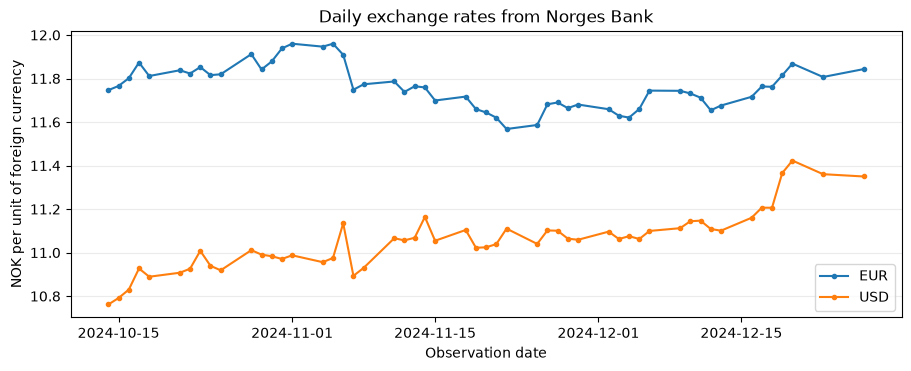

In [4]:
import matplotlib.pyplot as plt

# Mark the observation dates so published quotes are visible on the plot.
fig, ax = plt.subplots(figsize=(9, 3.6), layout='constrained')
ax.plot(exchange_rates.index, exchange_rates['eur_nok'], marker='.', label='EUR')
ax.plot(exchange_rates.index, exchange_rates['usd_nok'], marker='.', label='USD')
ax.set(title='Daily exchange rates from Norges Bank', xlabel='Observation date',
       ylabel='NOK per unit of foreign currency')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.show()

In the week of 23–29 December 2024, both series have quotes on 23 and 27 December. The weekly dataset will use the actual quote dates when it counts valid observations and aggregates the rates.

### 1.3 Load the NO3 source samples

Use the test period from section 1.1 for all three sources. Keep the NVE dates and the hourly timestamps from the source readers for inspection in the time-alignment section.

#### NVE Magasinstatistikk

Fetch NVE's public history with the [existing API reader](../dashboard/load_data.py) and select the NO3 price area. Keep the API's ISO year, ISO week, observation date and next-publication field alongside the filling measurements.

In [5]:
from dashboard.load_data import MAX_HISTORY_BYTES, fetch_json, prepare_history

# Keep the raw API response available for inspecting the original date fields.
nve_records, _ = fetch_json('HentOffentligData', MAX_HISTORY_BYTES)
nve_history = prepare_history(nve_records)
nve_selection = (
    nve_history['area_type'].eq(nve_area_type)
    & nve_history['area_number'].eq(nve_area_number)
    & nve_history['observation_date'].between(pd.Timestamp(test_start), pd.Timestamp(test_end), inclusive='left')
)
nve_weekly = nve_history.loc[nve_selection, [
    'observation_date', 'iso_year', 'iso_week', 'filling_fraction',
    'weekly_filling_change', 'next_publication_date',
]].reset_index(drop=True)
print(f'NVE returned {len(nve_weekly)} weekly observations for {region}.')
nve_weekly.head(3)

NVE returned 11 weekly observations for NO3.


,observation_date,iso_year,iso_week,filling_fraction,weekly_filling_change,next_publication_date
0,2024-10-20,2024,42,0.870708,0.004746,2024-10-30 13:00:00
1,2024-10-27,2024,43,0.905651,0.034929,2024-11-06 13:00:00
2,2024-11-03,2024,44,0.923453,0.017802,2024-11-13 13:00:00


#### Open-Meteo ERA5

Reuse the [saved NO3 hourly summary](../data/weather/NO3_era5_2024-01-01_2024-12-31_hourly.csv.gz) from Part 3. Each record includes the UTC timestamp, regional means for temperature and precipitation, and the number of sampled locations.

In [6]:
from dashboard.weather_data import read_weather_summary

# Validate the saved calendar-year summary before taking the sample.
weather_year = test_start.year
weather_history = read_weather_summary(region, date(weather_year, 1, 1), date(weather_year, 12, 31))
if weather_history is None:
    raise FileNotFoundError(f'The saved ERA5 summary for {region} in {weather_year} is missing.')
weather_selection = weather_history['time'].between(window_start, window_end, inclusive='left')
weather_hourly = weather_history.loc[weather_selection].reset_index(drop=True)
print(f'{len(weather_hourly):,} weather hours for {region}.')
weather_hourly.head(3)

1,849 weather hours for NO3.


,time,temperature_2m,precipitation,point_count
0,2024-10-13 22:00:00+00:00,3.7097,0.6045,1000
1,2024-10-13 23:00:00+00:00,3.5154,0.5293,1000
2,2024-10-14 00:00:00+00:00,3.3849,0.4395,1000


#### ENTSO-E transfers in MongoDB

Use the app's [read-only query](../dashboard/transfers.py) to load the saved 2024 data for NO3–SE2, then select the test period. A complete hour has a full 60 minutes of coverage and a valid energy value in each direction. The MongoDB connection reads the URI from the local `.streamlit/secrets.toml` file.

In [7]:
from dashboard.transfers import COLLECTION, DATABASE, complete_hours, read_year
from pipeline.entsoe_mongo import connect

# Use the existing MongoDB connection and bounded query for a single border and year.
with connect(project_root) as client:
    entsoe_history = read_year(client[DATABASE][COLLECTION], entsoe_connection, test_start.year)
entsoe_selection = (entsoe_history.index >= window_start) & (entsoe_history.index < window_end)
entsoe_hourly = entsoe_history.loc[entsoe_selection].copy()
complete = complete_hours(entsoe_hourly).sum()
print(f'{entsoe_connection} has {complete:,} of {len(entsoe_hourly):,} complete hours in the test period.')
entsoe_hourly.head(3)

NO3-SE2 has 1,849 of 1,849 complete hours in the test period.


,import_mwh,export_mwh,import_coverage_minutes,export_coverage_minutes
time_utc,,,,
2024-10-13 22:00:00+00:00,0.0,50.61,60.0,60.0
2024-10-13 23:00:00+00:00,0.0,69.85,60.0,60.0
2024-10-14 00:00:00+00:00,0.0,55.95,60.0,60.0
